This script showcases various methods of regression, beginning with the simplest, and progressing in complexity.

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from pathlib import Path
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

project_dir = Path.cwd()
data_dir = project_dir / 'Raw Data'
result_dict = {}

# Get data

In [2]:
# Get the raw data here:  
# https://www.kaggle.com/datasets/alinoranianesfahani/dataco-smart-supply-chain-for-big-data-analysis/code
    
# load single-store sales data
DataCoSupplyChainDataset = pd.read_csv(
    data_dir / 'DataCoSupplyChainDataset.csv',
    encoding='Latin-1',
    low_memory=False
)

# Wrangle

In [3]:
# load the dataset
df = DataCoSupplyChainDataset.copy()

# prepare numeric columns
numeric_cols = [
    "Order Item Quantity",
    "Order Item Product Price",
    "Order Item Discount",
    "Days for shipment (scheduled)",
    "Late_delivery_risk"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["order_date"] = pd.to_datetime(
    df["order date (DateOrders)"], errors="coerce"
)

# remove rows missing essential values
df = df.dropna(
    subset=[
        "Order Item Quantity",
        "Order Item Product Price",
        "Order Item Discount",
        "Days for shipment (scheduled)",
        "Late_delivery_risk",
        "order_date"
    ]
).copy()

# define a shared regression target and feature set
target = "Order Item Quantity"
features = [
    "Order Item Product Price",
    "Order Item Discount",
    "Days for shipment (scheduled)"
]

X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# define a common regression evaluation function
def evaluate_regression(name, model, X_test, y_test):
    predictions = model.predict(X_test)

    return {
        "model": name,
        "mae": mean_absolute_error(y_test, predictions),
        "rmse": np.sqrt(mean_squared_error(y_test, predictions)),
        "r2": r2_score(y_test, predictions)
    }


# 1. baseline modeling
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

baseline_results = evaluate_regression(
    "mean baseline", baseline, X_test, y_test
)


# 2. simple linear regression
simple_feature = ["Order Item Product Price"]

simple_model = LinearRegression()
simple_model.fit(X_train[simple_feature], y_train)

simple_results = evaluate_regression(
    "simple linear regression",
    simple_model,
    X_test[simple_feature],
    y_test
)


# 3. multiple linear regression
multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)

multiple_results = evaluate_regression(
    "multiple linear regression",
    multiple_model,
    X_test,
    y_test
)


# 4. machine learning regression
ml_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

ml_model.fit(X_train, y_train)

ml_results = evaluate_regression(
    "random forest regression",
    ml_model,
    X_test,
    y_test
)


# display regression comparison
regression_results = pd.DataFrame([
    baseline_results,
    simple_results,
    multiple_results,
    ml_results
])

display(regression_results.sort_values("mae"))

,model,mae,rmse,r2
3,random forest regression,0.454250,0.791795,0.703288
2,multiple linear regression,0.972615,1.171911,0.350021
1,simple linear regression,1.043176,1.273909,0.231955
0,mean baseline,1.269167,1.453634,-0.000046


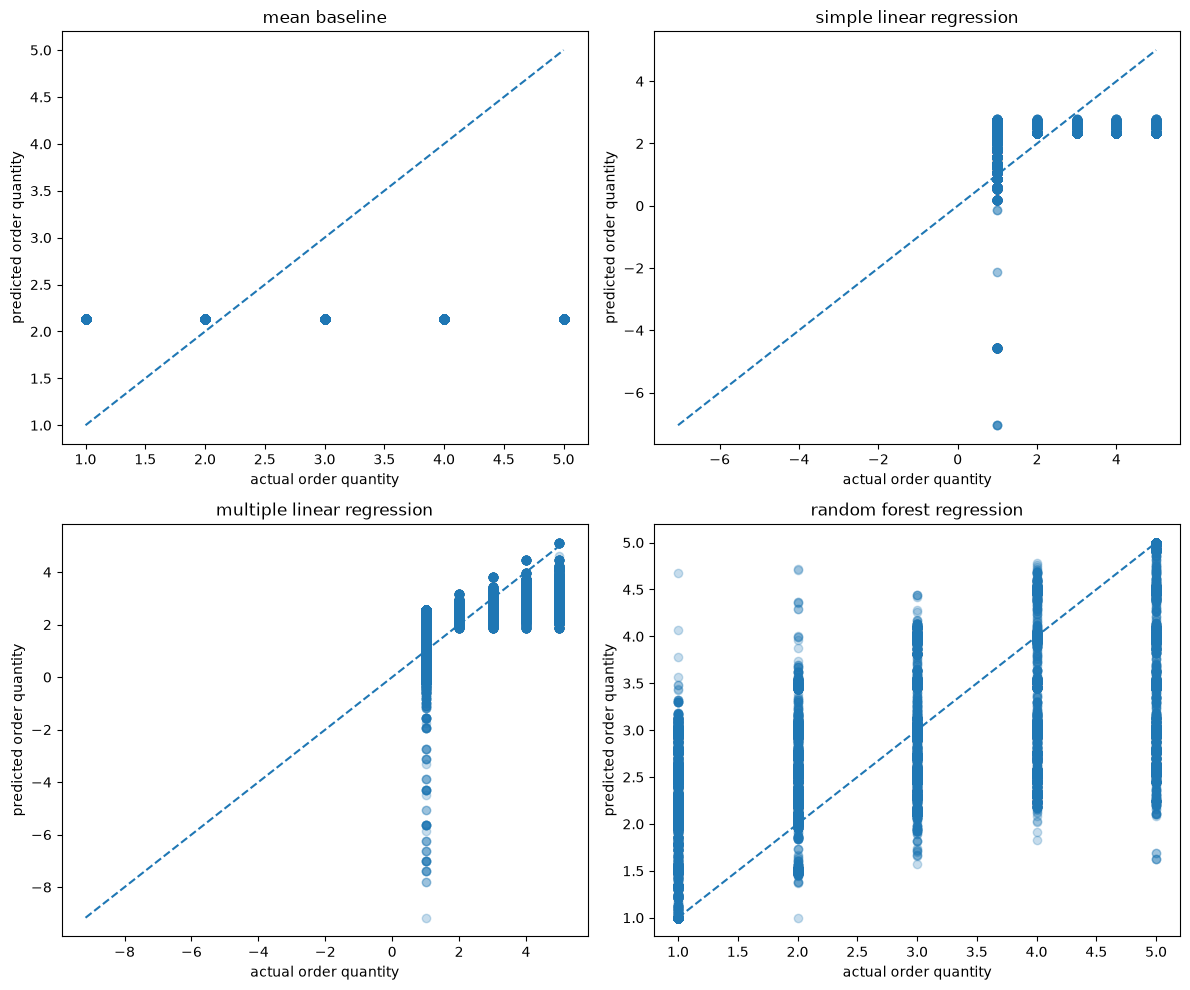

In [4]:
import matplotlib.pyplot as plt

# generate predictions from each model
predictions = {
    "mean baseline": baseline.predict(X_test),
    "simple linear regression": simple_model.predict(X_test[simple_feature]),
    "multiple linear regression": multiple_model.predict(X_test),
    "random forest regression": ml_model.predict(X_test)
}

# plot actual vs. predicted values for each model
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, y_pred, alpha=0.25)

    # add reference line for perfect predictions
    lower = min(y_test.min(), y_pred.min())
    upper = max(y_test.max(), y_pred.max())
    ax.plot([lower, upper], [lower, upper], linestyle="--")

    ax.set_title(name)
    ax.set_xlabel("actual order quantity")
    ax.set_ylabel("predicted order quantity")

plt.tight_layout()
plt.show()

Dots should cluster near the diagonal line.  
The farther a dot is from the line, the larger the prediction error.


A vertical band of dots means many records have the same actual quantity but the model predicts different values for them.

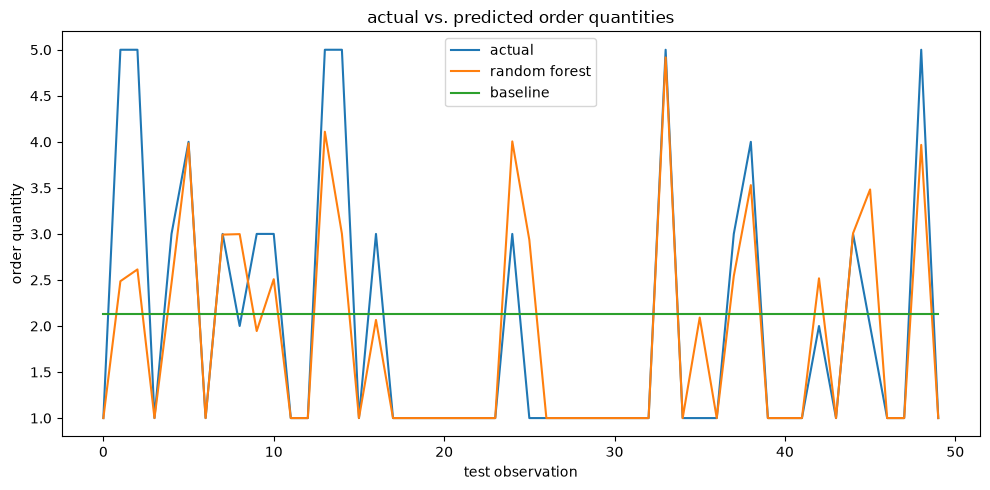

In [5]:
import matplotlib.pyplot as plt

# compare actual and predicted quantities for the first 50 test rows
n = 50

plt.figure(figsize=(10, 5))
plt.plot(y_test.iloc[:n].to_numpy(), label="actual")
plt.plot(ml_model.predict(X_test.iloc[:n]), label="random forest")
plt.plot(baseline.predict(X_test.iloc[:n]), label="baseline")

plt.title("actual vs. predicted order quantities")
plt.xlabel("test observation")
plt.ylabel("order quantity")
plt.legend()
plt.tight_layout()
plt.show()

# ML time series

In [6]:
# aggregate demand by product and date
daily_demand = (
    df.assign(date=df["order_date"].dt.normalize())
    .groupby(["Product Card Id", "date"], as_index=False)[target]
    .sum()
    .rename(columns={
        "Product Card Id": "product_id",
        target: "demand"
    })
)

# create a complete daily calendar for every product
all_dates = pd.date_range(
    daily_demand["date"].min(),
    daily_demand["date"].max(),
    freq="D"
)

products = daily_demand["product_id"].unique()

full_index = pd.MultiIndex.from_product(
    [products, all_dates],
    names=["product_id", "date"]
)

daily_demand = (
    daily_demand.set_index(["product_id", "date"])
    .reindex(full_index, fill_value=0)
    .reset_index()
    .sort_values(["product_id", "date"])
)

# create features using only previous demand
daily_demand["lag_1"] = (
    daily_demand.groupby("product_id")["demand"].shift(1)
)

daily_demand["lag_7"] = (
    daily_demand.groupby("product_id")["demand"].shift(7)
)

daily_demand["rolling_7"] = (
    daily_demand.groupby("product_id")["demand"]
    .transform(lambda x: x.shift(1).rolling(7).mean())
)

daily_demand["day_of_week"] = daily_demand["date"].dt.dayofweek
daily_demand["month"] = daily_demand["date"].dt.month

daily_demand = daily_demand.dropna().copy()

ts_features = [
    "lag_1",
    "lag_7",
    "rolling_7",
    "day_of_week",
    "month"
]

# use a chronological split to prevent future dates leaking into training
split_date = daily_demand["date"].quantile(0.8)

ts_train = daily_demand[daily_demand["date"] <= split_date]
ts_test = daily_demand[daily_demand["date"] > split_date]

X_ts_train = ts_train[ts_features]
y_ts_train = ts_train["demand"]
X_ts_test = ts_test[ts_features]
y_ts_test = ts_test["demand"]

ts_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

ts_model.fit(X_ts_train, y_ts_train)
ts_predictions = ts_model.predict(X_ts_test)

ts_results = {
    "model": "random forest time series",
    "mae": mean_absolute_error(y_ts_test, ts_predictions),
    "rmse": np.sqrt(mean_squared_error(y_ts_test, ts_predictions)),
    "r2": r2_score(y_ts_test, ts_predictions)
}

display(pd.DataFrame([ts_results]))

,model,mae,rmse,r2
0,random forest time series,0.966674,4.996077,0.696049


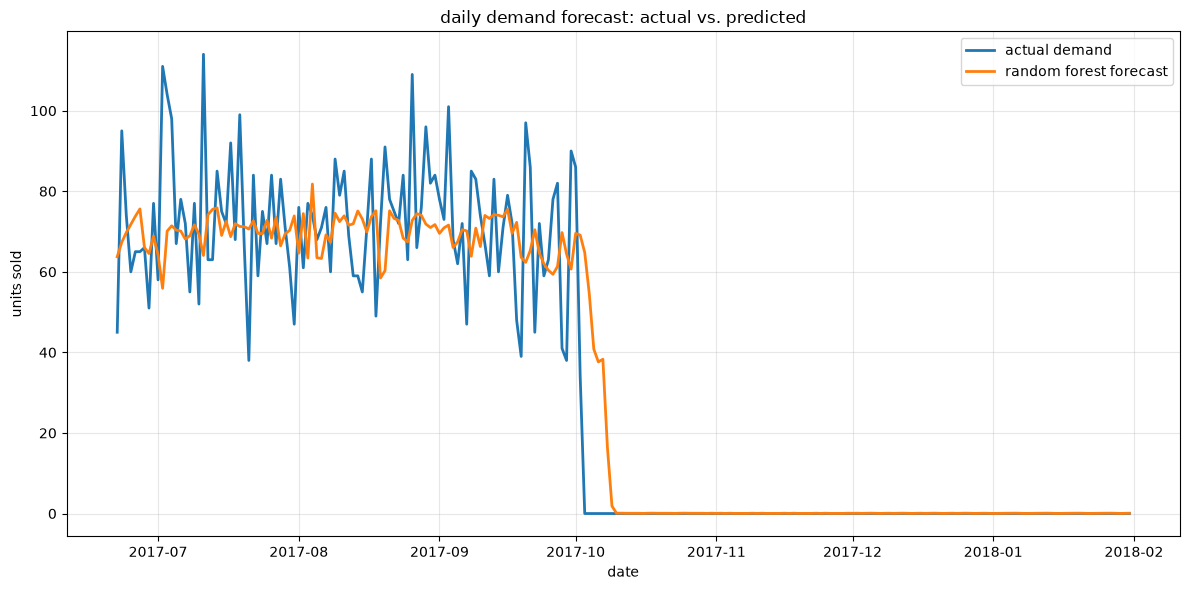

In [7]:
import matplotlib.pyplot as plt

# combine test dates, actual demand, and predictions
ts_plot = ts_test[["date", "product_id", "demand"]].copy()
ts_plot["predicted"] = ts_predictions

# select the product with the most demand for a readable example
product_id = (
    ts_plot.groupby("product_id")["demand"]
    .sum()
    .idxmax()
)

plot_data = (
    ts_plot[ts_plot["product_id"] == product_id]
    .sort_values("date")
)

# plot actual vs. predicted demand
plt.figure(figsize=(12, 6))
plt.plot(
    plot_data["date"],
    plot_data["demand"],
    label="actual demand",
    linewidth=2
)
plt.plot(
    plot_data["date"],
    plot_data["predicted"],
    label="random forest forecast",
    linewidth=2
)

plt.title("daily demand forecast: actual vs. predicted")
plt.xlabel("date")
plt.ylabel("units sold")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Logistic regression
Classification; late delivery risk

In [8]:
# use predictors available before delivery
classification_features = [
    "Order Item Quantity",
    "Order Item Product Price",
    "Order Item Discount",
    "Days for shipment (scheduled)",
    "Shipping Mode"
]

classification_target = "Late_delivery_risk"

classification_df = df.dropna(
    subset=classification_features + [classification_target]
).copy()

X_class = classification_df[classification_features]
y_class = classification_df[classification_target].astype(int)

# use a stratified split to preserve the class proportions
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_class,
    y_class,
    test_size=0.2,
    random_state=42,
    stratify=y_class
)

numeric_features = [
    "Order Item Quantity",
    "Order Item Product Price",
    "Order Item Discount",
    "Days for shipment (scheduled)"
]

categorical_features = ["Shipping Mode"]

preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

logistic_model.fit(Xc_train, yc_train)

class_predictions = logistic_model.predict(Xc_test)
class_probabilities = logistic_model.predict_proba(Xc_test)[:, 1]

print("logistic regression")
print("accuracy:", round(accuracy_score(yc_test, class_predictions), 3))
print("precision:", round(precision_score(yc_test, class_predictions, zero_division=0), 3))
print("recall:", round(recall_score(yc_test, class_predictions, zero_division=0), 3))
print("f1:", round(f1_score(yc_test, class_predictions, zero_division=0), 3))

if yc_test.nunique() == 2:
    print("roc auc:", round(roc_auc_score(yc_test, class_probabilities), 3))

logistic regression
accuracy: 0.697
precision: 0.85
recall: 0.543
f1: 0.662
roc auc: 0.731


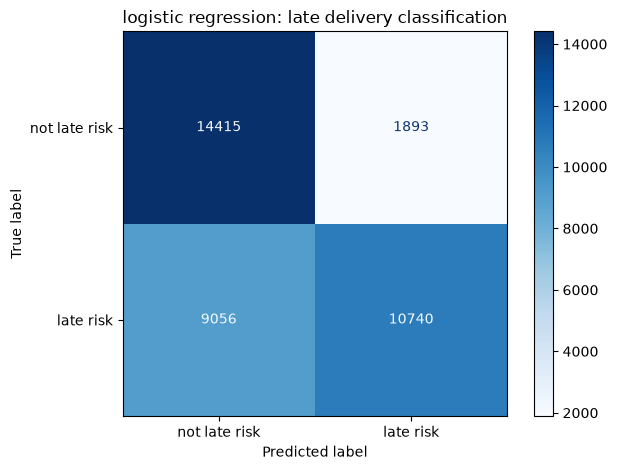

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# plot the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    yc_test,
    class_predictions,
    display_labels=["not late risk", "late risk"],
    cmap="Blues",
    values_format="d"
)

plt.title("logistic regression: late delivery classification")
plt.tight_layout()
plt.show()

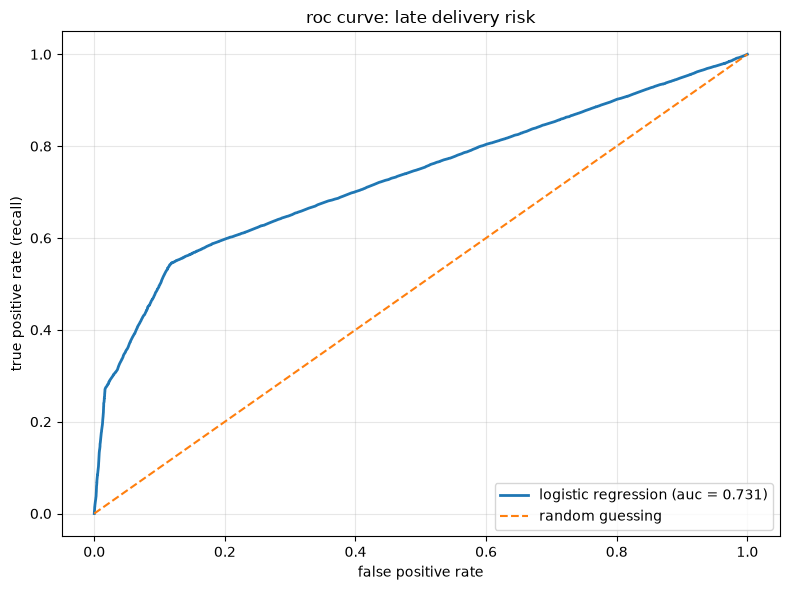

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# calculate the roc curve and auc
fpr, tpr, thresholds = roc_curve(yc_test, class_probabilities)
auc_score = roc_auc_score(yc_test, class_probabilities)

# plot the roc curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"logistic regression (auc = {auc_score:.3f})", linewidth=2)
plt.plot([0, 1], [0, 1], linestyle="--", label="random guessing")

plt.title("roc curve: late delivery risk")
plt.xlabel("false positive rate")
plt.ylabel("true positive rate (recall)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
print('done')

done
